Dynamic Regime Market Generated!
Every asset now has completely unpredictable regime durations, drifts, and volatilities.


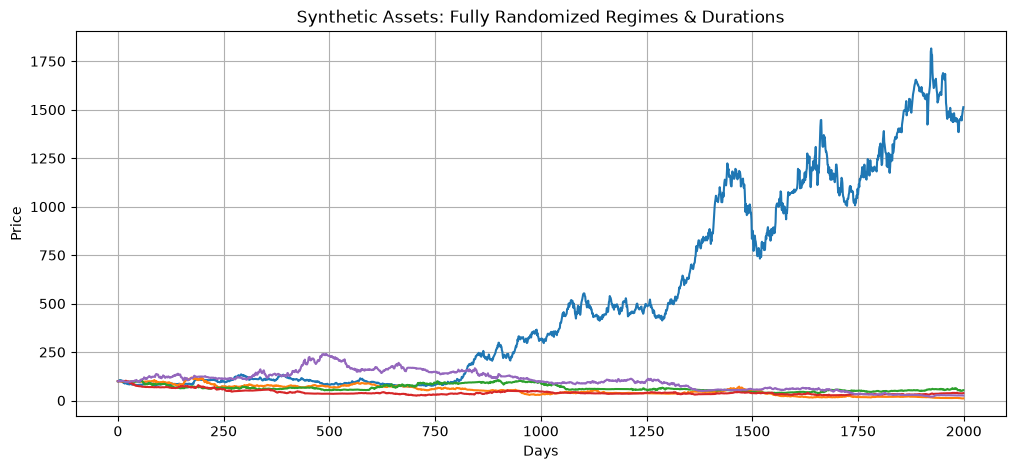

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
from msgbm_env import generate_dynamic_regime_market, SyntheticPortfolioEnv


# Generate 2000 time steps of the new dynamic regime data
returns_data, prices_data = generate_dynamic_regime_market()

print("Dynamic Regime Market Generated!")
print("Every asset now has completely unpredictable regime durations, drifts, and volatilities.")

# Optional: Plot the new chaotic price action to see the difference visually
plt.figure(figsize=(12, 5))
plt.plot(prices_data)
plt.title("Synthetic Assets: Fully Randomized Regimes & Durations")
plt.xlabel("Days")
plt.ylabel("Price")
plt.grid(True)
plt.show()

In [6]:
# ==========================================
# CELL 2: Environment & Metrics (from msgbm_env.py)
# ==========================================
# The environment is imported from msgbm_env.py to ensure the notebook
# and the validation test use the exact same code (prevents lookahead bias).
from msgbm_env import SyntheticPortfolioEnv


In [7]:
# Train/Test Split (First 1400 steps for training, last 600 for out-of-sample testing)
train_returns = returns_data[:1400]
test_returns = returns_data[1400:]

train_env = SyntheticPortfolioEnv(train_returns)
test_env = SyntheticPortfolioEnv(test_returns)

# Instantiate Stable-Baselines3 PPO Agent
# We use a slightly larger network to process the regime data
policy_kwargs = dict(net_arch=[128, 128])
model = PPO("MlpPolicy", train_env, verbose=0, learning_rate=0.0003, policy_kwargs=policy_kwargs)

print("Training RL Agent on Markov-Switching Data...")
# Increased timesteps slightly because regime switching is a harder problem to learn
model.learn(total_timesteps=150000)
print("Training Complete!")

Training RL Agent on Markov-Switching Data...
Training Complete!


ML OBJECTIVE METRICS
RL Agent:
  Sortino Ratio:      -0.0584
  Trade Expectancy:   -0.000557 per period
  Final Portfolio:    0.6773

Equal-Weight Benchmark:
  Sortino Ratio:      -0.0943
  Trade Expectancy:   -0.000558 per period
  Final Portfolio:    0.6765


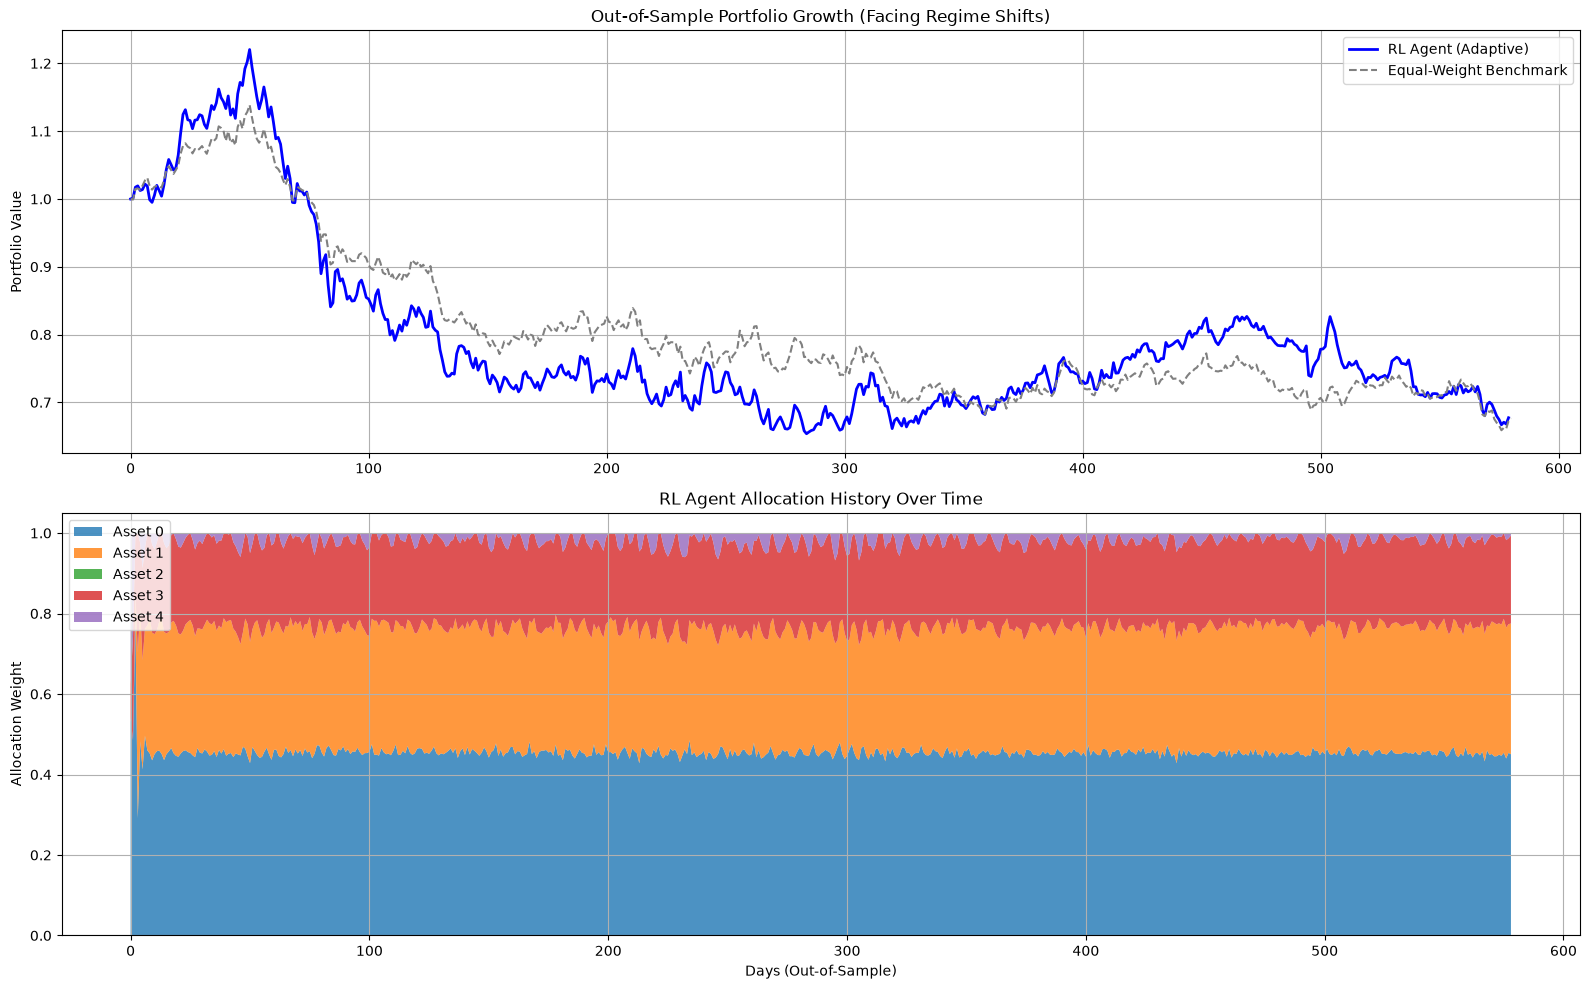

In [9]:
obs, _ = test_env.reset()
done = False

rl_values = [1.0]
rl_weights_history = []
rl_step_returns = []

# 1. Run RL Agent Backtest
while not done:
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    
    rl_values.append(info["portfolio_value"])
    rl_weights_history.append(info["weights"])
    rl_step_returns.append(info["step_return"])

# 2. Run Equal-Weight Benchmark (20% in each asset)
benchmark_values = [1.0]
bench_value = 1.0
tc = 0.0005
equal_weights = np.ones(5) / 5.0

for r in test_returns[20:]: # Match step window offset
    step_ret = np.dot(equal_weights, r)
    bench_value *= (1.0 + step_ret)
    benchmark_values.append(bench_value)


# ==========================================
# Print Objective Metrics
# ==========================================
from msgbm_env import compute_sortino_ratio, compute_trade_expectancy

rl_returns_arr = np.array(rl_step_returns)
bench_returns_arr = np.array([benchmark_values[i+1]/benchmark_values[i] - 1.0 
                           for i in range(len(benchmark_values)-1)])

rl_sortino = compute_sortino_ratio(rl_returns_arr)
rl_expectancy = compute_trade_expectancy(np.array(rl_values))

bench_sortino = compute_sortino_ratio(bench_returns_arr)
bench_expectancy = compute_trade_expectancy(np.array(benchmark_values))

print("" + "=" * 50)
print("ML OBJECTIVE METRICS")
print("=" * 50)
print(f"RL Agent:")
print(f"  Sortino Ratio:      {rl_sortino:+.4f}")
print(f"  Trade Expectancy:   {rl_expectancy:+.6f} per period")
print(f"  Final Portfolio:    {rl_values[-1]:.4f}")
print()
print(f"Equal-Weight Benchmark:")
print(f"  Sortino Ratio:      {bench_sortino:+.4f}")
print(f"  Trade Expectancy:   {bench_expectancy:+.6f} per period")
print(f"  Final Portfolio:    {benchmark_values[-1]:.4f}")
print("=" * 50)

# Plot Results
plt.figure(figsize=(16, 10))

# Subplot 1: Portfolio Growth
plt.subplot(2, 1, 1)
plt.plot(rl_values, label="RL Agent (Adaptive)", color="blue", linewidth=2)
plt.plot(benchmark_values, label="Equal-Weight Benchmark", color="gray", linestyle="--")
plt.title("Out-of-Sample Portfolio Growth (Facing Regime Shifts)")
plt.ylabel("Portfolio Value")
plt.legend()
plt.grid(True)

# Subplot 2: Dynamic Allocation
plt.subplot(2, 1, 2)
weights_df = pd.DataFrame(rl_weights_history, columns=[f"Asset {i}" for i in range(5)])
plt.stackplot(range(len(weights_df)), weights_df.T, labels=weights_df.columns, alpha=0.8)
plt.title("RL Agent Allocation History Over Time")
plt.xlabel("Days (Out-of-Sample)")
plt.ylabel("Allocation Weight")
plt.legend(loc="upper left")
plt.grid(True)

plt.tight_layout()
plt.show()